# Croston’s Method — From Scratch
### A guided, solved tutorial for intermittent demand forecasting

**Learning objectives:** Understand ADI and CV², distinguish actual demand from estimated demand size, follow the demand interval counter, calculate Z and P manually, and turn these estimates into a monthly forecast.

We use monthly demand, a smoothing factor of 0.2, and an initial interval of 1 month throughout the first worked example. These are illustrative choices, not universal defaults. This notebook covers **original Croston only**.

Run the code cells in order using **Shift + Enter**. All results and figures are also saved in the notebook.

## 1. Start with the demand history
A spare part is not consumed every month. There are three non-zero months in this six-month example.

| Month | Jan | Feb | Mar | Apr | May | Jun |
|---|---:|---:|---:|---:|---:|---:|
| Actual demand | 10 | 0 | 0 | 12 | 0 | 8 |

Croston asks two questions: **how much** is demanded when demand occurs, and **how frequently** does demand occur? It estimates these separately before combining them.

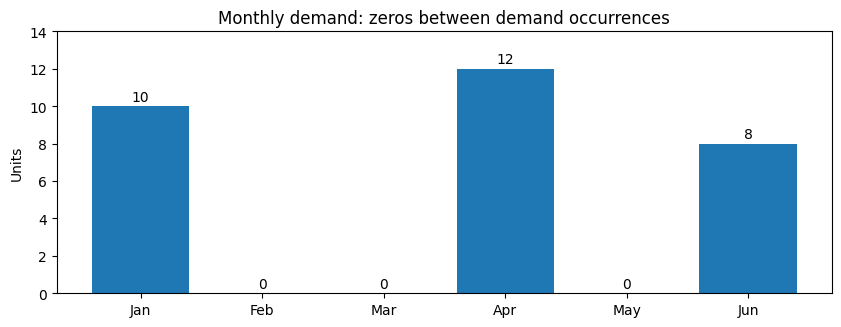

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline
months = ['Jan','Feb','Mar','Apr','May','Jun']
demand = np.array([10,0,0,12,0,8])
alpha = 0.2
plt.figure(figsize=(10,3.4))
plt.bar(months,demand)
for i,v in enumerate(demand): plt.text(i,v+0.3,str(v),ha='center')
plt.ylim(0,14); plt.ylabel('Units'); plt.title('Monthly demand: zeros between demand occurrences'); plt.show()

## 2. Classify the demand: ADI and CV²
ADI measures demand frequency; CV² measures the variability of **non-zero** demand sizes.

$$ADI=\frac{\text{number of periods}}{\text{number of non-zero periods}}=\frac{6}{3}=2$$

Non-zero quantities: 10, 12, 8. Their mean is 10, sample variance is $(0^2+2^2+(-2)^2)/(3-1)=4$, and sample standard deviation is 2.

$$CV^2=\left(\frac{2}{10}\right)^2=0.04$$

| Pattern | ADI | CV² |
|---|---|---|
| Smooth | < 1.32 | < 0.49 |
| Erratic | < 1.32 | ≥ 0.49 |
| Intermittent | ≥ 1.32 | < 0.49 |
| Lumpy | ≥ 1.32 | ≥ 0.49 |

Our SKU is **intermittent**. These conventional thresholds are from the Syntetos–Boylan–Croston classification; classification alone does not guarantee a best forecasting model. We study original Croston here.

ADI = 2.00; CV² = 0.0400


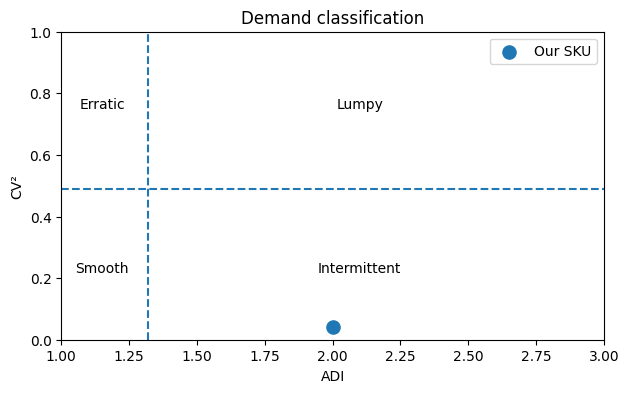

In [2]:
positive = demand[demand>0]
adi = len(demand)/len(positive)
cv2 = (positive.std(ddof=1)/positive.mean())**2
print(f'ADI = {adi:.2f}; CV² = {cv2:.4f}')
fig,ax=plt.subplots(figsize=(7,4))
ax.axvline(1.32,ls='--'); ax.axhline(.49,ls='--')
ax.scatter(adi,cv2,s=90,label='Our SKU',zorder=3)
for x,y,label in [(1.15,.75,'Erratic'),(2.1,.75,'Lumpy'),(1.15,.22,'Smooth'),(2.1,.22,'Intermittent')]: ax.text(x,y,label,ha='center')
ax.set(xlim=(1,3),ylim=(0,1),xlabel='ADI',ylabel='CV²',title='Demand classification'); ax.legend(); plt.show()

## 3. Estimated demand size (Z) — from scratch
**Z is not monthly demand.** It is the estimated quantity in a period when demand occurs.

Let $\alpha=0.2$. Whenever demand is positive, give 20% weight to the new observation and 80% to the previous estimate:

$$Z_t=\alpha D_t+(1-\alpha)Z_{t-1}$$

- **January:** first non-zero demand is 10. With no earlier estimate, initialize $Z_{Jan}=10$.
- **February:** zero demand. Carry forward $Z_{Feb}=10$.
- **March:** zero demand. Carry forward $Z_{Mar}=10$.
- **April:** actual demand is 12; previous estimate is 10 (carried forward from January).

$$Z_{Apr}=0.2(12)+0.8(10)=2.4+8=10.4$$

- **May:** zero demand. Carry forward $Z_{May}=10.4$.
- **June:** actual demand is 8. The previous estimate is **10.4, not 12**.

$$Z_{Jun}=0.2(8)+0.8(10.4)=1.6+8.32=9.92$$

| Month | Actual | Z calculation | Z |
|---|---:|---|---:|
| Jan | 10 | Initialize with first positive demand | 10 |
| Feb | 0 | Carry forward | 10 |
| Mar | 0 | Carry forward | 10 |
| Apr | 12 | 0.8 × 10 + 0.2 × 12 | 10.40 |
| May | 0 | Carry forward | 10.40 |
| Jun | 8 | 0.8 × 10.4 + 0.2 × 8 | 9.92 |

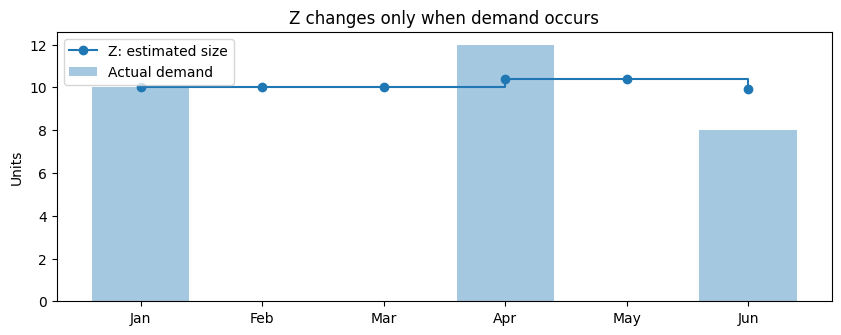

In [3]:
z_manual = [10,10,10,10.4,10.4,9.92]
plt.figure(figsize=(10,3.5)); plt.bar(months,demand,alpha=.4,label='Actual demand'); plt.step(months,z_manual,where='post',marker='o',label='Z: estimated size'); plt.ylabel('Units'); plt.title('Z changes only when demand occurs'); plt.legend(); plt.show()

## 4. Actual demand interval (Q) — count the months
This is the gap between two consecutive non-zero demand periods. Count the difference in month positions, not just the number of zero months.

January is month 1, April is month 4, June is month 6.

- Jan → Apr: $Q=4-1=3$ months (Feb, Mar, Apr).
- Apr → Jun: $Q=6-4=2$ months (May, Jun).

During zero-demand months, the elapsed-time counter grows. But **P does not change** until the next positive demand arrives. Q is only observed as a completed interval when demand occurs.

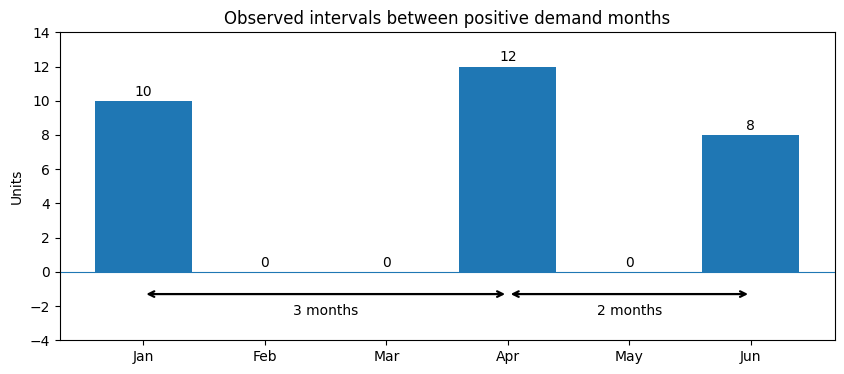

In [4]:
fig,ax=plt.subplots(figsize=(10,4)); x=np.arange(len(months)); ax.bar(x,demand)
ax.set_xticks(x,months); ax.set_ylim(-4,14); ax.axhline(0,lw=.8)
for i,v in enumerate(demand): ax.text(i,v+.3,str(v),ha='center')
for a,b in [(0,3),(3,5)]:
    ax.annotate('',xy=(b,-1.3),xytext=(a,-1.3),arrowprops={'arrowstyle':'<->','lw':1.6})
    ax.text((a+b)/2,-2.5,f'{b-a} months',ha='center')
ax.set_ylabel('Units'); ax.set_title('Observed intervals between positive demand months'); plt.show()

## 5. Estimated demand interval (P) — the complete guided solution
Q is the actual observed interval. P is a smoothed estimate of the typical interval. Like Z, P is only updated when actual demand is positive.

$$P_t=\alpha Q_t+(1-\alpha)P_{t-1}$$

### January — first demand
Actual demand = 10. No earlier demand is known. Initialize $P_{Jan}=1$ month. This is an assumption (equivalently, the first demand is in period 1 of this sample), not an observed gap between two events.

### February — zero demand
One month has elapsed since January. No completed interval is available. $P_{Feb}=1$.

### March — zero demand
Two months have elapsed since January. Still no completed interval. $P_{Mar}=1$.

### April — new demand
Actual demand = 12. Actual interval Q = 3 months. Previous estimated interval P = 1 month.

| Component | Weight | Calculation |
|---|---:|---:|
| Previous estimate | 80% | 0.8 × 1 = 0.8 |
| New observed interval | 20% | 0.2 × 3 = 0.6 |

$$P_{Apr}=0.8+0.6=1.4\text{ months}$$

### May — zero demand
One month has elapsed since April. No completed interval. Carry forward $P_{May}=1.4$.

### June — new demand
Actual demand = 8. New actual interval Q = 2 months. Previous P = 1.4, not 3.

$$P_{Jun}=0.8(1.4)+0.2(2)=1.12+0.4=1.52\text{ months}$$

| Month | Demand | Elapsed months (before reset) | Completed Q | P calculation | P |
|---|---:|---:|---:|---|---:|
| Jan | 10 | — | — | Initialize | 1.00 |
| Feb | 0 | 1 | — | Carry forward | 1.00 |
| Mar | 0 | 2 | — | Carry forward | 1.00 |
| Apr | 12 | 3 | 3 | 0.8 × 1 + 0.2 × 3 | 1.40 |
| May | 0 | 1 | — | Carry forward | 1.40 |
| Jun | 8 | 2 | 2 | 0.8 × 1.4 + 0.2 × 2 | 1.52 |

**Key insight:** the elapsed-time counter and P are different things. The counter increases through zero-demand months; P stays fixed. The counter resets when demand occurs.

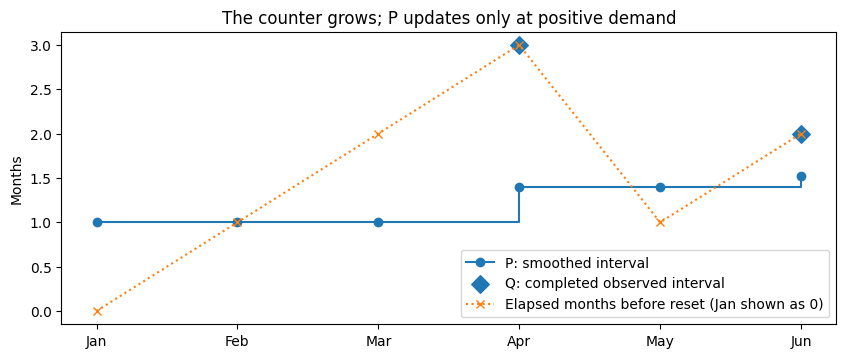

In [5]:
p_manual=[1,1,1,1.4,1.4,1.52]
plt.figure(figsize=(10,3.8)); plt.step(months,p_manual,where='post',marker='o',label='P: smoothed interval'); plt.scatter([3,5],[3,2],marker='D',s=80,label='Q: completed observed interval'); plt.plot(months,[0,1,2,3,1,2],ls=':',marker='x',label='Elapsed months before reset (Jan shown as 0)'); plt.ylabel('Months'); plt.title('The counter grows; P updates only at positive demand'); plt.legend(); plt.show()

## 6. Combine Z and P into the Croston forecast
$$F_t=\frac{Z_t}{P_t}$$

Z is units per positive-demand period, P is months per demand occurrence, and F is **expected average units per month**.

For example, if demand is 12 units every 3 months, the average rate is 4 units/month, even though actual monthly demands are 12, 0, 0, … . Croston predicts a rate, not the exact month or size of the next order.

At the end of April: $F_{Apr}=10.4/1.4=7.4286$ units/month, available to forecast May.

At the end of June: $F_{Jun}=9.92/1.52=6.5263$ units/month, available to forecast July.

| Month | Actual | Z | P | F after observing month |
|---|---:|---:|---:|---:|
| Jan | 10 | 10 | 1 | 10.00 |
| Feb | 0 | 10 | 1 | 10.00 |
| Mar | 0 | 10 | 1 | 10.00 |
| Apr | 12 | 10.4 | 1.4 | 7.43 |
| May | 0 | 10.4 | 1.4 | 7.43 |
| Jun | 8 | 9.92 | 1.52 | 6.53 |

Do not compare a post-update forecast against the actual demand used to calculate it. A genuine one-step-ahead forecast for a month uses the previous month's state.

## 7. Implement Croston in Python
The function below stores the forecast **before** observing demand and the updated forecast **after** observing it. It handles leading zeros, rejects invalid inputs, and leaves the forecast undefined until the first positive observation. By default the initial interval is the first positive period's 1-based position; an explicit initial interval can also be supplied.

In [6]:
def croston(values, alpha=0.2, initial_interval=None):
    values=np.asarray(values,dtype=float)
    if values.ndim!=1 or not len(values) or not np.isfinite(values).all() or (values<0).any():
        raise ValueError('Provide a nonempty sequence of finite nonnegative demands.')
    if not 0<alpha<=1: raise ValueError('alpha must be in (0, 1].')
    if initial_interval is not None and (not np.isfinite(initial_interval) or initial_interval<1):
        raise ValueError('Initial interval must be at least 1.')
    z=p=np.nan; last=None; rows=[]
    for t,d in enumerate(values):
        before=z/p if last is not None else np.nan
        elapsed=t-last if last is not None else np.nan
        q=np.nan
        if d>0:
            if last is None:
                z=d; p=t+1 if initial_interval is None else initial_interval
                action='Initialize'
            else:
                q=t-last
                z=alpha*d+(1-alpha)*z
                p=alpha*q+(1-alpha)*p
                action='Update Z and P'
            last=t
        else:
            action='Carry forward' if last is not None else 'Await first demand'
        rows.append({'Actual':d,'Elapsed':elapsed,'Q':q,'Z':z,'P':p,'Forecast_before':before,'Forecast_after':z/p if last is not None else np.nan,'Action':action})
    return pd.DataFrame(rows)
result=croston(demand,alpha,initial_interval=1).set_axis(months)
display(result.round(4))
assert np.allclose(result.Z,z_manual)
assert np.allclose(result.P,p_manual)
assert np.allclose(result.Forecast_before.iloc[1:],result.Forecast_after.iloc[:-1])

,Actual,Elapsed,Q,Z,P,Forecast_before,Forecast_after,Action
Jan,10.0,NaN,NaN,10.00,1.00,NaN,10.0000,Initialize
Feb,0.0,1.0,NaN,10.00,1.00,10.0000,10.0000,Carry forward
Mar,0.0,2.0,NaN,10.00,1.00,10.0000,10.0000,Carry forward
Apr,12.0,3.0,3.0,10.40,1.40,10.0000,7.4286,Update Z and P
May,0.0,1.0,NaN,10.40,1.40,7.4286,7.4286,Carry forward
Jun,8.0,2.0,2.0,9.92,1.52,7.4286,6.5263,Update Z and P


,Forecast (units/month)
Jul,6.5263
Aug,6.5263
Sep,6.5263
Oct,6.5263
Nov,6.5263
Dec,6.5263


Six-month forecast total: 39.1579 units


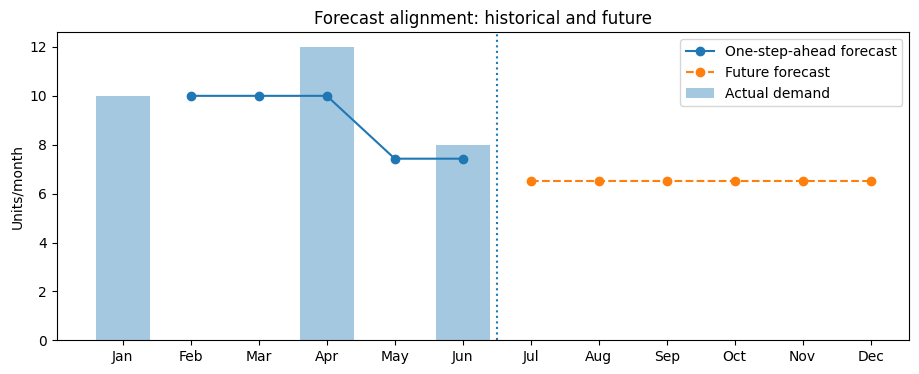

In [7]:
future=['Jul','Aug','Sep','Oct','Nov','Dec']
f=result.Forecast_after.iloc[-1]
forecast=pd.Series(f,index=future,name='Forecast (units/month)')
display(forecast.round(4).to_frame()); print(f'Six-month forecast total: {6*f:.4f} units')
fig,ax=plt.subplots(figsize=(11,4)); ax.bar(months,demand,alpha=.4,label='Actual demand'); ax.plot(months,result.Forecast_before,marker='o',label='One-step-ahead forecast'); ax.plot(future,forecast,marker='o',ls='--',label='Future forecast'); ax.axvline(5.5,ls=':'); ax.set_ylabel('Units/month'); ax.set_title('Forecast alignment: historical and future'); ax.legend(); plt.show()

## 8. Second solved example — extend to 12 months
Use the original full-year history: 10, 0, 0, 12, 0, 8, 0, 0, 15, 0, 10, 0. Continue from June's Z = 9.92 and P = 1.52.

Try calculating September and November yourself before running the next cell.

### Worked solution
July and August: carry forward Z and P.

September (Q = 3):
$$Z=0.2(15)+0.8(9.92)=10.936$$
$$P=0.2(3)+0.8(1.52)=1.816$$
October: carry forward.

November (Q = 2):
$$Z=0.2(10)+0.8(10.936)=10.7488$$
$$P=0.2(2)+0.8(1.816)=1.8528$$
December: carry forward. Next January forecast is $10.7488/1.8528\approx5.80$ units/month.

,Actual,Elapsed,Q,Z,P,Forecast_before,Forecast_after,Action
Jan,10.0,NaN,NaN,10.0000,1.0000,NaN,10.0000,Initialize
Feb,0.0,1.0,NaN,10.0000,1.0000,10.0000,10.0000,Carry forward
Mar,0.0,2.0,NaN,10.0000,1.0000,10.0000,10.0000,Carry forward
Apr,12.0,3.0,3.0,10.4000,1.4000,10.0000,7.4286,Update Z and P
May,0.0,1.0,NaN,10.4000,1.4000,7.4286,7.4286,Carry forward
Jun,8.0,2.0,2.0,9.9200,1.5200,7.4286,6.5263,Update Z and P
Jul,0.0,1.0,NaN,9.9200,1.5200,6.5263,6.5263,Carry forward
Aug,0.0,2.0,NaN,9.9200,1.5200,6.5263,6.5263,Carry forward
Sep,15.0,3.0,3.0,10.9360,1.8160,6.5263,6.0220,Update Z and P
Oct,0.0,1.0,NaN,10.9360,1.8160,6.0220,6.0220,Carry forward


Next January forecast: 5.8014


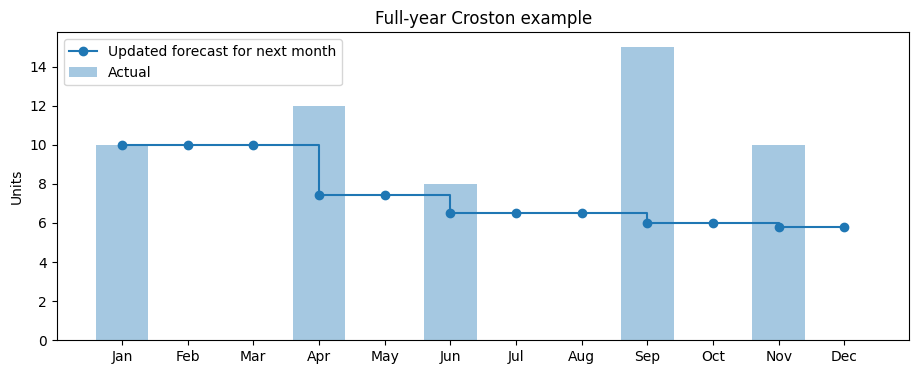

In [8]:
year_months=months+future
annual=[10,0,0,12,0,8,0,0,15,0,10,0]
year=croston(annual,.2,1).set_axis(year_months)
display(year.round(4)); print(f"Next January forecast: {year.Forecast_after.iloc[-1]:.4f}")
plt.figure(figsize=(11,4)); plt.bar(year_months,annual,alpha=.4,label='Actual'); plt.step(year_months,year.Forecast_after,where='post',marker='o',label='Updated forecast for next month'); plt.ylabel('Units'); plt.title('Full-year Croston example'); plt.legend(); plt.show()

## 9. Practice: change the smoothing factor
A larger alpha gives more weight to recent positive demand sizes and completed intervals. The same alpha is used for both estimates in this tutorial. Change the values below and rerun. Select alpha and initialization using time-ordered validation on real data, not just the final forecast magnitude.

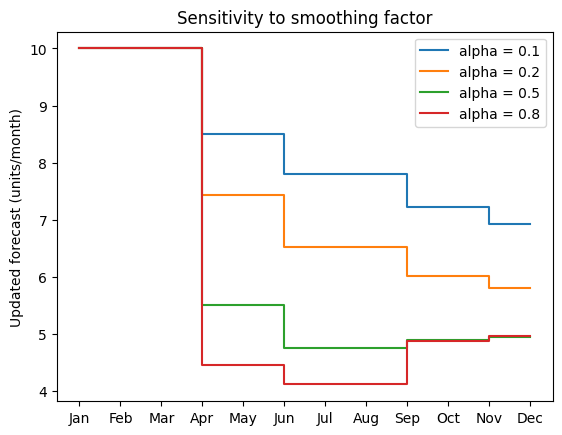

In [9]:
for a in [0.1,0.2,0.5,0.8]:
    r=croston(annual,a,1)
    plt.step(year_months,r.Forecast_after,where='post',label=f'alpha = {a}')
plt.ylabel('Updated forecast (units/month)'); plt.title('Sensitivity to smoothing factor'); plt.legend(); plt.show()

## 10. Revision and limitations
- **D:** actual demand in the current period.
- **Q:** completed actual interval between positive demand periods.
- **Z:** estimated size when demand occurs.
- **P:** estimated interval between occurrences.
- **F = Z/P:** expected demand rate per period.

At zero demand, keep Z and P unchanged; elapsed time grows. At positive demand, calculate Q, update Z and P, then reset the elapsed counter. The updated forecast applies to the next period.

Original Croston may overestimate the long-run demand rate and does not automatically decay after prolonged zero demand. It does not predict the precise timing of the next order or supply a prediction interval. Initial estimates can strongly affect short histories. CV² with sample variance requires at least two positive observations; ADI is undefined as a finite value when all demand is zero. This tutorial does not implement bias corrections or other models.

**References:** Croston, J. D. (1972), *Forecasting and stock control for intermittent demands*, Operational Research Quarterly, 23(3), 289–303. Syntetos, A. A., Boylan, J. E., and Croston, J. D. (2005), *On the categorization of demand patterns*, Journal of the Operational Research Society, 56, 495–503.